# 01 · Xenium breast cancer: cell-type annotation

**Data:** 10x Xenium, FFPE breast cancer, replicate 1 (Janesick et al., *Nat Commun* 2023), 313-gene panel. One patient, one section.

**Steps**

1. Load the counts and cell centroids into one `AnnData`.
2. Quality control: drop cells with very few transcripts.
3. Normalize, log-transform and scale.
4. PCA, k-nearest-neighbor graph, UMAP.
5. Leiden clustering; choose the resolution by marker coherence.
6. Marker genes per cluster, canonical markers, clusters on the tissue.
7. Name the clusters by hand, with a check that each name fits its cluster.
8. Spatial check: cell-type maps and neighborhood enrichment. Save.

## Parameters
All tunable values in one place. The random seed is fixed.

In [1]:
from pathlib import Path

DATA_DIR    = Path("data/xenium_breast")
RESULTS_DIR = Path("results")
FIG_DIR     = RESULTS_DIR / "figures"

MIN_COUNTS  = 10      # initial QC threshold; inspect distributions before changing it
N_PCS       = 30      # PCs used for the kNN graph
N_NEIGHBORS = 15      # neighbors in the kNN graph
RESOLUTIONS = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2]
N_TOP       = 5       # top-ranked genes used in the coherence heuristic
MIN_DEPTH   = 50      # clusters with median raw counts below this are flagged, not automatically discarded
MIN_COHER   = 0.30    # heuristic threshold for marker coherence; not a universal biological standard
SEED        = 0

In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score

sc.settings.verbosity = 1
FIG_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# record the software versions of this run (a fixed seed alone does not guarantee identical results across versions)
import sys
from importlib.metadata import version
print("python", sys.version.split()[0])
print({p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "scanpy", "anndata",
                                "squidpy", "igraph", "leidenalg", "matplotlib"]})

python 3.13.17
{'numpy': '2.4.6', 'pandas': '3.0.5', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'scanpy': '1.12.4', 'anndata': '0.13.4', 'squidpy': '1.8.3', 'igraph': '1.0.0', 'leidenalg': '0.12.0', 'matplotlib': '3.11.2'}


**Reproducibility.** Leiden results depend on library versions, not only on the seed. With Python 3.9 and older scanpy/igraph/leidenalg,
the rule below selects resolution 0.8 (18 clusters) and the annotation check stops the notebook, as designed. The cluster names are valid
for the versions printed above (pinned in `requirements-lock.txt`). In another environment, rebuild the dictionary from that run's markers.

## 1 · Load the data

- `xe1_cell_feature_matrix.h5` holds the counts. `gex_only=True` keeps the 313 genes and drops the
  negative-control probes, negative-control codewords and blank codewords.
- `xe1_cells.csv.gz` has one row per cell, with the centroid (µm) and QC values. Its `cell_id` matches the matrix barcodes.

In [4]:
# Load the cell-by-gene count matrix. Keep gene-expression features only.
adata = sc.read_10x_h5(DATA_DIR / "xe1_cell_feature_matrix.h5", gex_only=True)
adata.var_names_make_unique()

# Load cell metadata and use cell_id as the index so rows can be aligned to barcodes.
cells = pd.read_csv(DATA_DIR / "xe1_cells.csv.gz")
cells["cell_id"] = cells["cell_id"].astype(str)
cells = cells.set_index("cell_id")

# Fail clearly if any matrix barcode has no matching metadata row.
missing = adata.obs_names.difference(cells.index)
if len(missing):
    raise ValueError(f"{len(missing)} expression-matrix cells are missing from the metadata table.")

# Align metadata to the exact order of the expression matrix.
adata.obs = cells.loc[adata.obs_names].copy()
adata.obsm["spatial"] = adata.obs[["x_centroid", "y_centroid"]].to_numpy()

adata

AnnData object with n_obs × n_vars = 167780 × 313
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area'
    var: 'gene_ids', 'feature_types', 'genome'
    obsm: 'spatial'
    layers: None (.X)

In [5]:
adata.obs.head()   # one row per cell: centroid (µm), transcript counts, control counts, cell area

,x_centroid,y_centroid,transcript_counts,control_probe_counts,control_codeword_counts,total_counts,cell_area,nucleus_area
1,847.259912,326.191365,28,1,0,29,58.387031,26.642187
2,826.341995,328.031830,94,0,0,94,197.016719,42.130781
3,848.766919,331.743187,9,0,0,9,16.256250,12.688906
4,824.228409,334.252643,11,0,0,11,42.311406,10.069844
5,841.357538,332.242505,48,0,0,48,107.652500,37.479687


## 2 · Quality control

A cell with very few transcripts carries too little information to annotate. `MIN_COUNTS = 10` is the threshold used in Xenium benchmarks
(Salas et al., 2025); here it removes about 2% of cells. All 313 genes are kept: the panel is small and curated.

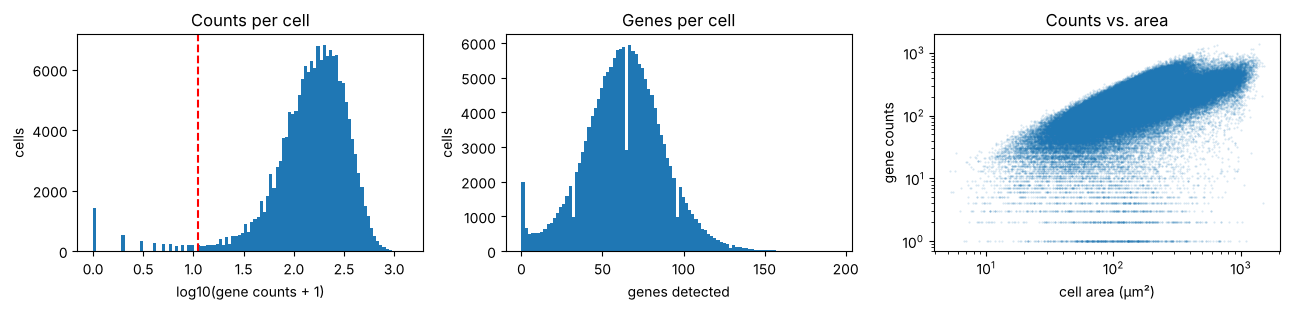

In [6]:
# Calculate QC metrics on the original count matrix.
sc.pp.calculate_qc_metrics(adata, percent_top=None, inplace=True)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].hist(np.log10(adata.obs["total_counts"] + 1), bins=100)
ax[0].axvline(np.log10(MIN_COUNTS + 1), color="red", ls="--")
ax[0].set(xlabel="log10(gene counts + 1)", ylabel="cells", title="Counts per cell")
ax[1].hist(adata.obs["n_genes_by_counts"], bins=100)
ax[1].set(xlabel="genes detected", ylabel="cells", title="Genes per cell")
ax[2].scatter(adata.obs["cell_area"], adata.obs["total_counts"], s=0.2, alpha=0.2, rasterized=True)
ax[2].set(xscale="log", yscale="log", xlabel="cell area (µm²)", ylabel="gene counts", title="Counts vs. area")
plt.tight_layout()
plt.show()

In [7]:
n_before = adata.n_obs
sc.pp.filter_cells(adata, min_counts=MIN_COUNTS)
print(f"kept {adata.n_obs:,} of {n_before:,} cells ({n_before - adata.n_obs:,} removed)")

kept 164,000 of 167,780 cells (3,780 removed)


**Negative controls.** Xenium panels include negative-control probes and blank codewords. Their share of all decoded counts
estimates the false-positive rate.

In [8]:
ctrl = adata.obs["control_probe_counts"] + adata.obs["control_codeword_counts"]
print(f"control counts / all decoded counts: {ctrl.sum() / (adata.obs['transcript_counts'] + ctrl).sum():.3%}")

control counts / all decoded counts: 0.095%


The control rate is far below 1%, so no control-based filter is needed.

**Segmentation caveat.** The onboard segmentation expands each nucleus outward, so some transcripts are assigned to a neighboring cell
(Salas et al., 2025). Small cells packed against large ones (immune cells in tumor or stroma) are most affected. The KDE check in notebook 03 is one way to find them.

## 3 · Normalize and scale

1. Keep the raw counts in `layers["counts"]`.
2. **Library size:** scale each cell to the median total count (`normalize_total`), then `log1p`. Kept in `layers["lognorm"]` for markers and plots.
3. **Scale** each gene to mean 0, SD 1 (clipped at 10) for PCA.

No highly-variable-gene selection: the panel has only 313 genes. Library size + log + scale was the best clustering workflow in a Xenium benchmark (Salas et al., 2025).
**Limitation:** with a targeted panel, library size depends on which genes are on the panel, and area normalization is an alternative (Atta et al., 2024). Labels at fuzzy borders (CAFs vs. fibroblasts, proliferating vs. invasive tumor) are the ones most likely to depend on this choice.

In [9]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
adata.layers["lognorm"] = adata.X.copy()
sc.pp.scale(adata, max_value=10)

/usr/local/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


## 4 · PCA, neighbor graph, UMAP

The elbow of the variance curve guides `N_PCS`. The same PCs are used later for the KDE.

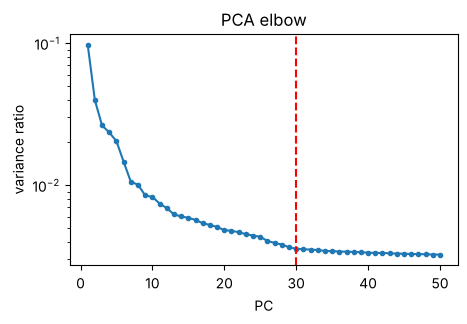

first 30 PCs explain 35.9% of the total variance


In [10]:
sc.tl.pca(adata, n_comps=50, random_state=SEED)

vr = adata.uns["pca"]["variance_ratio"]
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(np.arange(1, 51), vr, "o-", ms=3)
ax.axvline(N_PCS, color="red", ls="--")
ax.set(xlabel="PC", ylabel="variance ratio", yscale="log", title="PCA elbow")
plt.show()
print(f"first {N_PCS} PCs explain {vr[:N_PCS].sum():.1%} of the total variance")

In [11]:
sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)

## 5 · Leiden clustering and the choice of resolution

Leiden is run at several resolutions. For each cluster `k`, *marker coherence* asks whether its top `N_TOP` genes (t-test) are detected more often inside than outside the cluster:

$$s_k = \frac{1}{N_{\text{top}}}\sum_g \left(\text{frac}_{g,\,\text{in } k} - \text{frac}_{g,\,\text{out of } k}\right)$$

Clusters with median counts below `MIN_DEPTH` are low-depth and do not count in the rule. This is a heuristic for cluster separation, not proof of a cell type.

In [12]:
detected = adata.layers["counts"] > 0   # cell x gene: gene detected?

def cluster_summary(adata, key):
    """Size, median raw counts, coherence and top genes of each cluster."""
    sc.tl.rank_genes_groups(adata, key, method="t-test", layer="lognorm", key_added="rg_tmp")
    labels = adata.obs[key].to_numpy()
    rows = []
    for k in adata.obs[key].cat.categories:
        top = list(adata.uns["rg_tmp"]["names"][k][:N_TOP])
        idx = [adata.var_names.get_loc(g) for g in top]
        inside = labels == k
        f_in = np.asarray(detected[inside][:, idx].mean(axis=0)).ravel()
        f_out = np.asarray(detected[~inside][:, idx].mean(axis=0)).ravel()
        rows.append({"cluster": k, "n_cells": int(inside.sum()),
                     "median_counts": float(np.median(adata.obs["total_counts"][inside])),
                     "coherence": float((f_in - f_out).mean()), "top_markers": " ".join(top)})
    del adata.uns["rg_tmp"]
    return pd.DataFrame(rows).set_index("cluster")

rows, summaries = [], {}
for r in RESOLUTIONS:
    sc.tl.leiden(adata, resolution=r, key_added=f"leiden_{r}", flavor="igraph",
                 n_iterations=2, directed=False, random_state=SEED)
    s = summaries[r] = cluster_summary(adata, f"leiden_{r}")
    eligible = s[s["median_counts"] >= MIN_DEPTH]
    rows.append({"resolution": r, "n_clusters": len(s), "n_low_depth": len(s) - len(eligible),
                 "min_coherence": eligible["coherence"].min(),
                 "passes": bool(eligible["coherence"].min() >= MIN_COHER)})
scan = pd.DataFrame(rows).set_index("resolution")

# stability: agreement with the next resolution (not biological validity)
scan["ARI_to_next"] = [adjusted_rand_score(adata.obs[f"leiden_{a}"], adata.obs[f"leiden_{b}"])
                       for a, b in zip(RESOLUTIONS[:-1], RESOLUTIONS[1:])] + [np.nan]
scan.round(3)

,n_clusters,n_low_depth,min_coherence,passes,ARI_to_next
resolution,,,,,
0.2,11,0,0.371,True,0.901
0.4,13,0,0.268,False,0.798
0.6,18,1,0.354,True,0.892
0.8,20,1,0.308,True,0.888
1.0,22,1,0.355,True,0.846
1.2,24,1,0.286,False,NaN


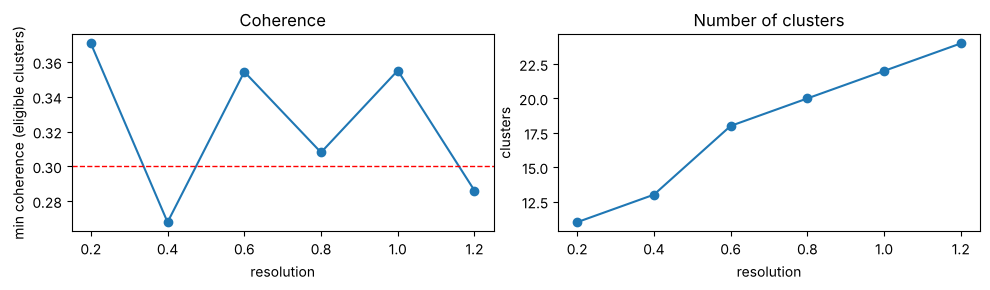

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(scan.index, scan["min_coherence"], "o-")
ax[0].axhline(MIN_COHER, color="red", ls="--", lw=1)
ax[0].set(xlabel="resolution", ylabel="min coherence (eligible clusters)", title="Coherence")
ax[1].plot(scan.index, scan["n_clusters"], "o-")
ax[1].set(xlabel="resolution", ylabel="clusters", title="Number of clusters")
plt.tight_layout()
plt.show()

**Choice of resolution:** the highest tested resolution at which every non-low-depth cluster has coherence ≥ `MIN_COHER` (0.30, an operational value).
The highest passing one leans toward splitting; naming can undo an over-split by giving two clusters the same name.
If no resolution passes, the code stops instead of choosing silently.

In [14]:
passing = scan.index[scan["passes"]]
if len(passing) == 0:
    raise ValueError("No resolution passed the coherence rule: review the scan before choosing one by hand.")

RESOLUTION = float(max(passing))
adata.obs["cluster"] = adata.obs[f"leiden_{RESOLUTION}"].copy()
summary = summaries[RESOLUTION]
print(f"Selected resolution: {RESOLUTION}")
summary.round(2)

Selected resolution: 1.0


,n_cells,median_counts,coherence,top_markers
cluster,,,,
0,4170,30.0,-0.04,ERBB2 KRT8 S100A14 ELF5 KRT7
1,5152,186.0,0.58,FCER1G CD68 APOC1 LYZ HAVCR2
2,8524,189.0,0.40,POSTN LUM PDGFRB RUNX1 ACTA2
3,12000,137.0,0.60,FGL2 CD4 LYZ FCER1G AIF1
4,19148,93.0,0.63,IL7R TRAC CD3E PTPRC CXCR4
5,12278,214.5,0.36,KRT8 ERBB2 EPCAM KRT7 TACSTD2
6,23958,225.0,0.44,EPCAM KRT7 FOXA1 FASN GATA3
7,6125,161.0,0.62,MYLK KRT14 DST KRT5 ACTA2
8,7962,260.0,0.48,EPCAM FOXA1 KRT7 FASN TOP2A


## 6 · Marker evidence for each cluster

- **Ranking:** Wilcoxon rank-sum test, each cluster against all other cells (log-normalized expression).
- **Table:** top eight genes per cluster, with the fraction of cells detecting each gene inside / outside the cluster.
- **Dot plot:** canonical breast-tissue markers grouped by expected cell type.

In [15]:
sc.tl.rank_genes_groups(adata, "cluster", method="wilcoxon", layer="lognorm")
ranked = sc.get.rank_genes_groups_df(adata, group=None)
ranked.to_csv(RESULTS_DIR / "xenium_markers.csv", index=False)

labels = adata.obs["cluster"].to_numpy()
def with_fractions(k, genes):
    inside = labels == k
    idx = [adata.var_names.get_loc(g) for g in genes]
    f_in = np.asarray(detected[inside][:, idx].mean(axis=0)).ravel()
    f_out = np.asarray(detected[~inside][:, idx].mean(axis=0)).ravel()
    return ", ".join(f"{g} ({a:.2f}/{b:.2f})" for g, a, b in zip(genes, f_in, f_out))

markers = summary[["n_cells", "median_counts"]].copy()
markers["top 8 markers (frac in/out)"] = [with_fractions(k, ranked.loc[ranked["group"] == k, "names"].head(8).tolist())
                                          for k in markers.index]
with pd.option_context("display.max_colwidth", 180):
    display(markers)

,n_cells,median_counts,top 8 markers (frac in/out)
cluster,,,
0,4170,30.0,"ERBB2 (0.86/0.88), KRT8 (0.55/0.57), KRT7 (0.62/0.67), MMP12 (0.04/0.02), ELF5 (0.05/0.03), SLC4A1 (0.02/0.01), CYP1A1 (0.01/0.01), TACSTD2 (0.44/0.57)"
1,5152,186.0,"APOC1 (0.81/0.12), FCER1G (0.92/0.31), CD68 (0.91/0.30), LYZ (0.84/0.36), HAVCR2 (0.64/0.11), C1QC (0.68/0.17), IGSF6 (0.66/0.17), FCGR3A (0.61/0.12)"
2,8524,189.0,"POSTN (0.99/0.54), LUM (0.99/0.60), PDGFRB (0.82/0.25), ACTA2 (0.87/0.56), RUNX1 (0.86/0.56), MMP2 (0.78/0.33), CRISPLD2 (0.61/0.20), PDGFRA (0.68/0.24)"
3,12000,137.0,"FGL2 (0.89/0.21), LYZ (0.89/0.33), CD4 (0.89/0.30), FCER1G (0.86/0.29), AIF1 (0.83/0.25), CD163 (0.72/0.15), PDK4 (0.81/0.34), CD68 (0.79/0.28)"
4,19148,93.0,"IL7R (0.87/0.18), TRAC (0.88/0.21), CD3E (0.88/0.16), PTPRC (0.89/0.29), CXCR4 (0.90/0.44), CYTIP (0.68/0.18), CD4 (0.73/0.29), S100A4 (0.70/0.31)"
5,12278,214.5,"TACSTD2 (0.97/0.53), KRT8 (0.98/0.54), S100A14 (0.90/0.43), CEACAM6 (0.90/0.38), CCND1 (0.99/0.76), CDH1 (0.92/0.46), ERBB2 (1.00/0.87), DSP (0.88/0.42)"
6,23958,225.0,"FASN (0.98/0.45), EPCAM (0.99/0.53), FOXA1 (0.99/0.55), KRT7 (1.00/0.61), ABCC11 (0.85/0.25), MLPH (0.95/0.40), ANKRD30A (0.96/0.55), GATA3 (0.99/0.60)"
7,6125,161.0,"KRT14 (0.96/0.11), MYLK (0.98/0.25), DST (0.97/0.60), KRT5 (0.87/0.07), PTN (0.78/0.14), MYH11 (0.74/0.07), ACTA2 (0.93/0.56), SERPINA3 (0.89/0.34)"
8,7962,260.0,"TOP2A (0.92/0.18), CENPF (0.86/0.13), EPCAM (0.99/0.58), PCLAF (0.83/0.21), FOXA1 (0.99/0.59), FASN (0.98/0.50), MKI67 (0.75/0.12), MLPH (0.93/0.46)"


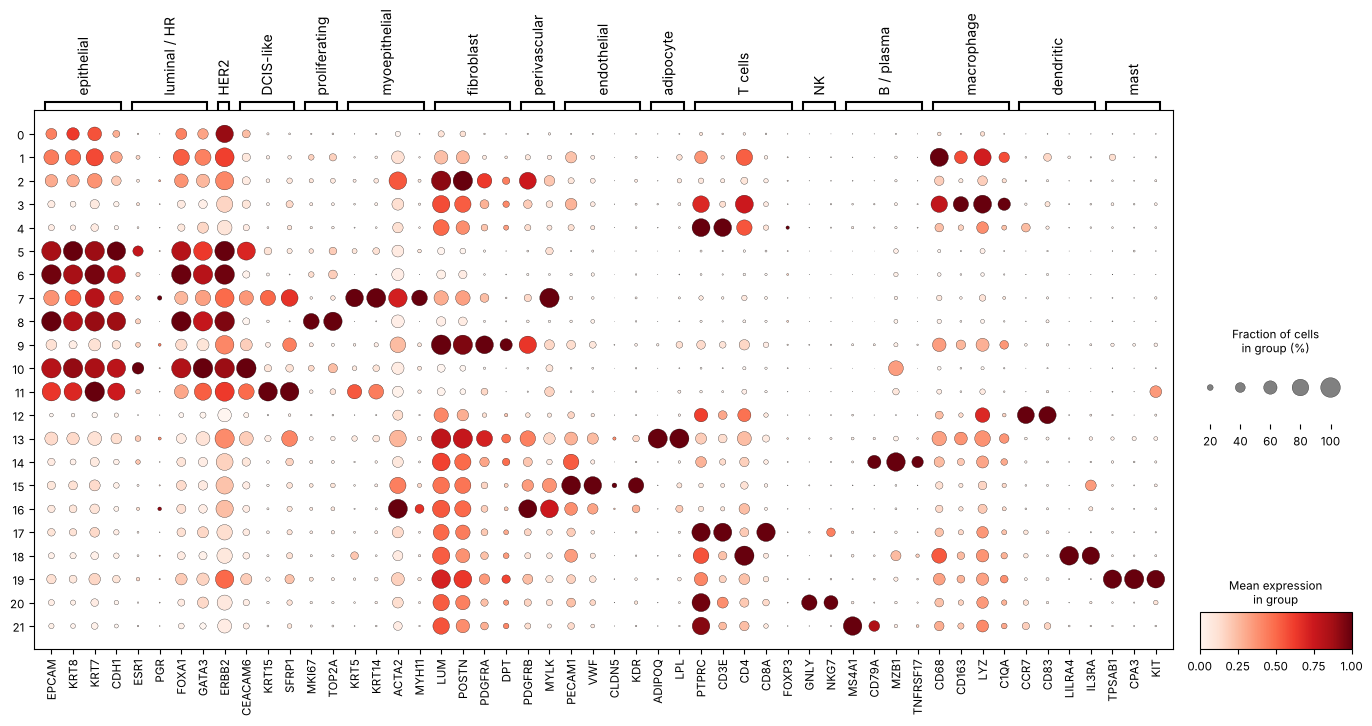

In [16]:
# Canonical markers grouped by expected cell type.
canonical = {
    "epithelial":     ["EPCAM", "KRT8", "KRT7", "CDH1"],
    "luminal / HR":   ["ESR1", "PGR", "FOXA1", "GATA3"],
    "HER2":           ["ERBB2"],
    "DCIS-like":      ["CEACAM6", "KRT15", "SFRP1"],
    "proliferating":  ["MKI67", "TOP2A"],
    "myoepithelial":  ["KRT5", "KRT14", "ACTA2", "MYH11"],
    "fibroblast":     ["LUM", "POSTN", "PDGFRA", "DPT"],
    "perivascular":   ["PDGFRB", "MYLK"],
    "endothelial":    ["PECAM1", "VWF", "CLDN5", "KDR"],
    "adipocyte":      ["ADIPOQ", "LPL"],
    "T cells":        ["PTPRC", "CD3E", "CD4", "CD8A", "FOXP3"],
    "NK":             ["GNLY", "NKG7"],
    "B / plasma":     ["MS4A1", "CD79A", "MZB1", "TNFRSF17"],
    "macrophage":     ["CD68", "CD163", "LYZ", "C1QA"],
    "dendritic":      ["CCR7", "CD83", "LILRA4", "IL3RA"],
    "mast":           ["TPSAB1", "CPA3", "KIT"],
}
missing_markers = sorted({g for genes in canonical.values() for g in genes} - set(adata.var_names))
if missing_markers:
    raise ValueError(f"Canonical markers missing from the panel: {missing_markers}")

dp = sc.pl.dotplot(
    adata, canonical, groupby="cluster", layer="lognorm",
    standard_scale="var", figsize=(17, 7), show=False, return_fig=True
)
dp.savefig(FIG_DIR / "xenium_canonical_dotplot.png", dpi=120)
plt.show()

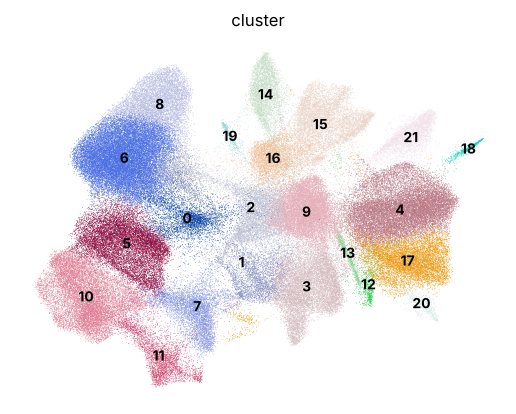

In [17]:
sc.pl.umap(adata, color="cluster", legend_loc="on data", size=1, frameon=False)

### Where each cluster sits in the tissue

Spatial position is evidence too. DCIS cells sit inside ducts ringed by myoepithelial cells,
while invasive tumor cells spread into the stroma. Each panel highlights one cluster on the whole section.

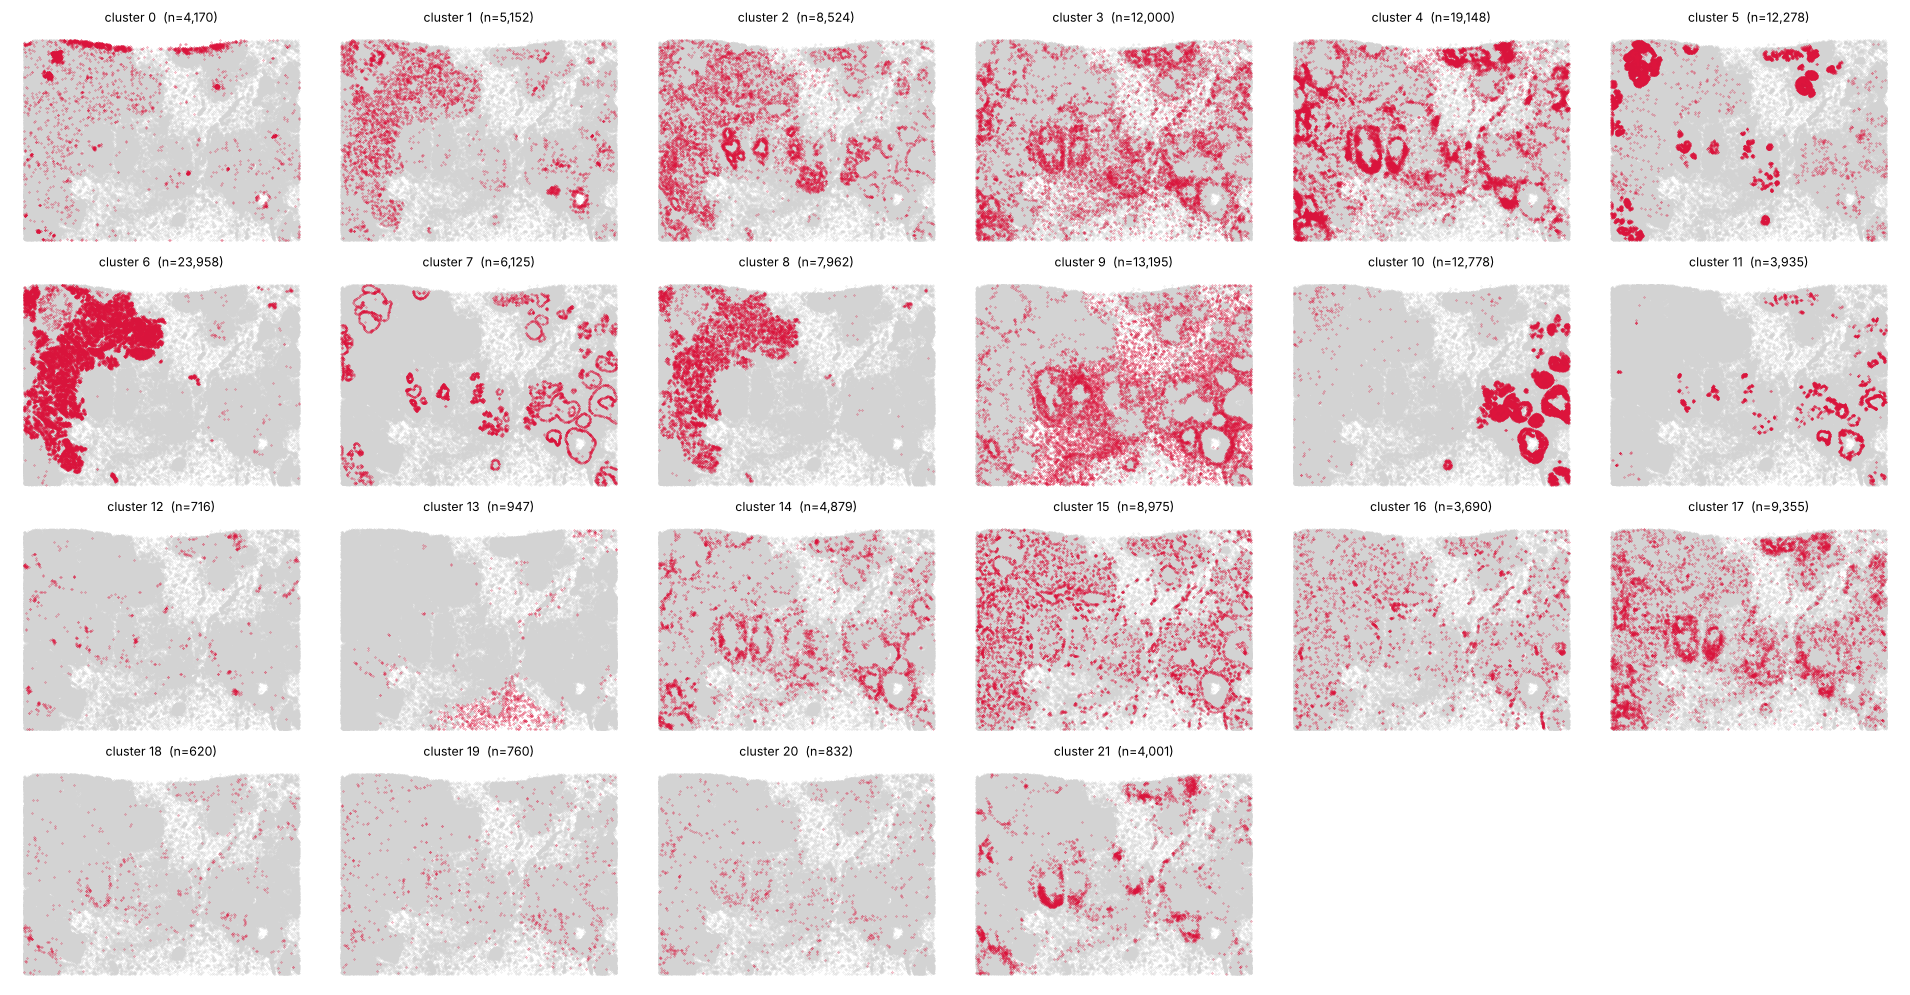

In [18]:
xy = adata.obsm["spatial"]
cl = adata.obs["cluster"].to_numpy()
cats = adata.obs["cluster"].cat.categories
ncol = 6
nrow = int(np.ceil(len(cats) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 2.5 * nrow))
for ax, k in zip(axes.flat, cats):
    m = cl == k
    ax.scatter(xy[~m, 0], xy[~m, 1], s=0.05, c="lightgrey", rasterized=True)
    ax.scatter(xy[m, 0], xy[m, 1], s=0.05, c="crimson", rasterized=True)
    ax.set_title(f"cluster {k}  (n={m.sum():,})", fontsize=9)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")
for ax in axes.flat[len(cats):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "xenium_clusters_on_tissue.png", dpi=120)
plt.show()

## 7 · My annotation

Each cluster is named by hand from three pieces of evidence: the top-marker table, the canonical-marker
dot plot and the tissue maps above. The evidence for each name is in the comment.

- Clusters that share an identity get the same name only if their markers **and** their tissue
  position agree. Otherwise they keep separate names (e.g. two DCIS groups in different ducts).
- Clusters without a clear identity are named `unknown`.

In [19]:
# cluster -> (my name, key marker). The key marker is the gene the name rests on; it is checked below.
annotation = {
    # --- epithelial / tumor ---
    "6":  ("Invasive tumor",               "FASN"),     # FASN, FOXA1, ABCC11, ANKRD30A; one large sheet growing into stroma
    "8":  ("Proliferating invasive tumor", "TOP2A"),    # TOP2A, CENPF, MKI67 + the invasive markers; same sheet as cluster 6
    "5":  ("DCIS 1",                       "TACSTD2"),  # TACSTD2, S100A14, CEACAM6, ERBB2; compact round nests (ducts)
    "10": ("DCIS 2",                       "CEACAM6"),  # CEACAM6, GATA3, CD9, TPD52; large ducts on the right, ringed by myoepithelium
    "7":  ("Myoepithelial",                "KRT14"),    # KRT14, KRT5, ACTA2, MYH11; thin rings around ducts
    "11": ("Myoepithelial KRT15+",         "KRT15"),    # KRT15, SFRP1, KRT23, KRT6B; at duct edges, weaker KRT5/KRT14
    # --- stroma ---
    "2":  ("CAF / myofibroblasts",         "POSTN"),    # POSTN, ACTA2, PDGFRB, RUNX1; concentrated around ducts and tumor
    "9":  ("Fibroblasts",                  "LUM"),      # LUM, CXCL12, DPT, FBLN1, IGF1; diffuse stroma
    "16": ("Perivascular",                 "ACTA2"),    # ACTA2, PDGFRB, CAV1, ANGPT2, AVPR1A
    "15": ("Endothelial",                  "PECAM1"),   # PECAM1, VWF, CD93, KDR, CLEC14A
    "13": ("Adipocytes",                   "ADIPOQ"),   # ADIPOQ, LPL, PPARG, ADH1B; fatty region at the bottom
    # --- lymphoid ---
    "4":  ("CD4+ T cells",                 "CD4"),      # IL7R, TRAC, CD3E, CD4
    "17": ("CD8+ T cells",                 "CD8A"),     # CD8A, CD8B, CCL5, GZMA
    "20": ("NK cells",                     "KLRD1"),    # KLRD1, KLRF1, GNLY, NKG7; no CD3E
    "21": ("B cells",                      "MS4A1"),    # MS4A1, BANK1, CD19, CD79A
    "14": ("Plasma cells",                 "MZB1"),     # MZB1, TENT5C, SLAMF7, PRDM1
    # --- myeloid ---
    "1":  ("Macrophages APOC1+",           "APOC1"),    # APOC1, C1QC, CD68, HAVCR2, FCGR3A
    "3":  ("Macrophages CD163+",           "CD163"),    # FGL2, CD163, AIF1, LYZ
    "12": ("Mature DCs",                   "CCR7"),     # CCR7, CD83, DUSP5
    "18": ("pDCs",                         "LILRA4"),   # LILRA4, IL3RA, GZMB, PTGDS
    "19": ("Mast cells",                   "CPA3"),     # CPA3, TPSAB1, KIT, HDC
    # --- unclear ---
    "0":  ("unknown",                      None),       # low depth (median ~30 counts), mostly at the tissue edge
}

# every cluster must be named exactly once
assert set(annotation) == set(adata.obs["cluster"].cat.categories), "cluster set changed: re-check the names"

# safeguard: the resolution is chosen in code, and Leiden numbering can change with library versions.
# Each key marker must be among the top 10 Wilcoxon markers (section 6) of its cluster.
top10 = {k: list(adata.uns["rank_genes_groups"]["names"][k][:10]) for k in annotation}
bad = {k: (name, key) for k, (name, key) in annotation.items() if key and key not in top10[k]}
assert not bad, f"key markers not found in their clusters' top markers, re-check the names: {bad}"
print(f"resolution {RESOLUTION}: all key markers found in their cluster's top-10 markers")

adata.obs["cell_type"] = adata.obs["cluster"].map({k: v[0] for k, v in annotation.items()}).astype("category")
adata.obs["cell_type"].value_counts().to_frame("n_cells")

resolution 1.0: all key markers found in their cluster's top-10 markers


,n_cells
cell_type,
Invasive tumor,23958
CD4+ T cells,19148
Fibroblasts,13195
DCIS 2,12778
DCIS 1,12278
Macrophages CD163+,12000
CD8+ T cells,9355
Endothelial,8975
CAF / myofibroblasts,8524


A fixed color per cell type, shared by every plot in this notebook (and reused in notebooks 03–04).
Related types get related colors: tumor in reds and pinks, myoepithelium in black and grey (so the duct rings stand out), stroma in browns and greens, lymphoid in blues, myeloid in purples and oranges.

In [20]:
palette = {
    "Invasive tumor": "#d62728", "Proliferating invasive tumor": "#8c1010",
    "DCIS 1": "#ff9896", "DCIS 2": "#f7b6d2",
    "Myoepithelial": "#000000", "Myoepithelial KRT15+": "#7f7f7f",
    "CAF / myofibroblasts": "#8c564b", "Fibroblasts": "#c49c94", "Perivascular": "#bcbd22",
    "Endothelial": "#2ca02c", "Adipocytes": "#ffdd57",
    "CD4+ T cells": "#1f77b4", "CD8+ T cells": "#17becf", "NK cells": "#9edae5",
    "B cells": "#393b79", "Plasma cells": "#6b6ecf",
    "Macrophages APOC1+": "#9467bd", "Macrophages CD163+": "#7b4173",
    "Mature DCs": "#ff7f0e", "pDCs": "#ffbb78", "Mast cells": "#e7ba52",
    "unknown": "#d9d9d9",
}
order = list(palette)                                     # display order
adata.obs["cell_type"] = adata.obs["cell_type"].cat.reorder_categories(order)
adata.uns["cell_type_colors"] = [palette[c] for c in order]

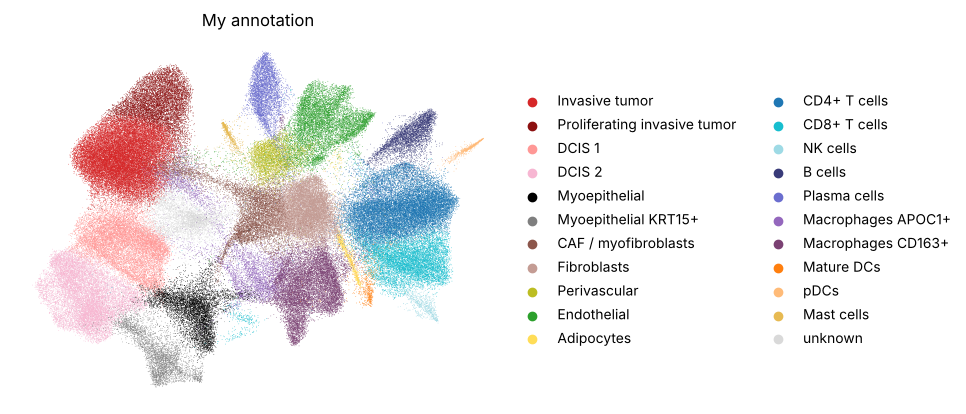

In [21]:
sc.pl.umap(adata, color="cell_type", size=1, frameon=False, title="My annotation")

**Check of the naming.** The dot plot, now grouped by cell type, should show each type lighting up
its own canonical markers, with few off-diagonal blocks.

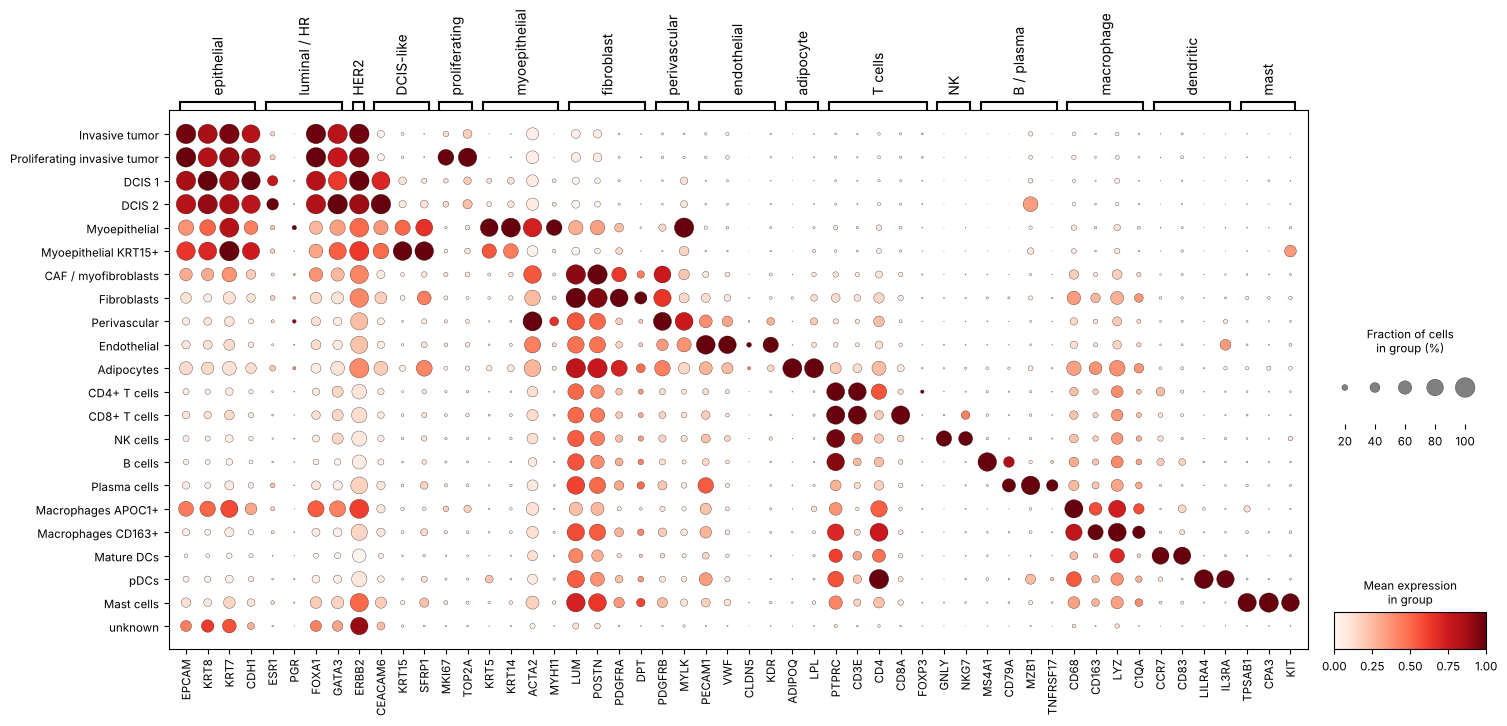

In [22]:
dp = sc.pl.dotplot(adata, canonical, groupby="cell_type", layer="lognorm",
                   standard_scale="var", figsize=(17, 7), show=False, return_fig=True)
dp.savefig(FIG_DIR / "xenium_celltype_dotplot.png", dpi=120)
plt.show()

## 8 · Spatial check

The labels were assigned from expression alone. Their position on the tissue is an independent test:

1. **Maps.** Tumor types should form coherent structures (ducts, sheets), not salt-and-pepper noise.
   Myoepithelial cells should ring the DCIS ducts.
2. **Neighborhood enrichment** (squidpy). For each pair of types, are cells of type A found next to
   type B more often than expected if labels were shuffled across the tissue? The z-score compares
   the observed count of A–B neighbor pairs with its permutation distribution.

**Reading the z-scores.** They grow with the number of cells, so with about 160,000 cells almost every pair is "significant".
They are used here to rank pairs and to compare patterns (which partner is strongest, which pairs are depleted), not as p-values.

**What a spatial pattern can and cannot show.** It supports spatial consistency of the labels, which is evidence not used to assign them. It does not establish identity by itself: real biology can break expected patterns, and this is a single section from one patient, so nothing here is replicated across patients.

In [23]:
NEIGH_RADIUS = 30     # µm, spatial neighbor radius (about two cell diameters)
N_PERMS      = 200    # permutations for neighborhood enrichment
ZOOM_SIZE    = 1500   # µm, side of the zoomed-in window

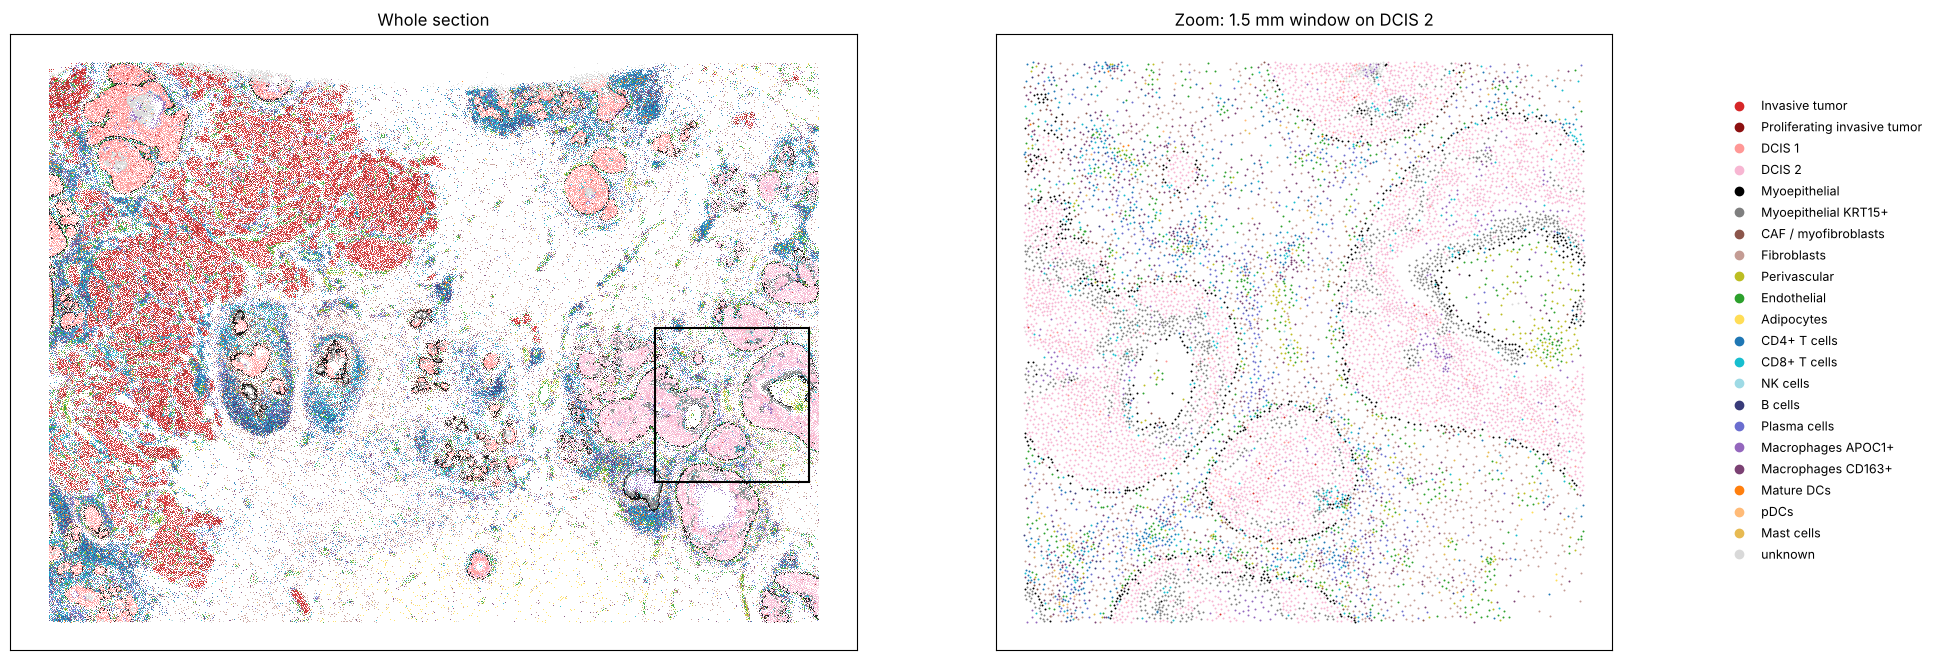

In [24]:
def plot_types(ax, xy, labels, title, s=0.1):
    # scatter cells colored by cell type, image orientation (y down)
    for c in order:
        m = labels == c
        if m.any():
            ax.scatter(xy[m, 0], xy[m, 1], s=s, c=palette[c], label=c, rasterized=True, linewidths=0)
    ax.set_aspect("equal"); ax.invert_yaxis()
    ax.set(title=title, xticks=[], yticks=[])

xy = adata.obsm["spatial"]
labels = adata.obs["cell_type"].to_numpy()

# zoom window: centered on the DCIS 2 ducts (data-driven, no hand-picked coordinates)
cx, cy = np.median(xy[labels == "DCIS 2"], axis=0)
box = (np.abs(xy[:, 0] - cx) < ZOOM_SIZE / 2) & (np.abs(xy[:, 1] - cy) < ZOOM_SIZE / 2)

fig, ax = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={"width_ratios": [1.4, 1]})
plot_types(ax[0], xy, labels, "Whole section", s=0.4)
ax[0].add_patch(plt.Rectangle((cx - ZOOM_SIZE / 2, cy - ZOOM_SIZE / 2), ZOOM_SIZE, ZOOM_SIZE,
                              fill=False, ec="black", lw=1.5))
plot_types(ax[1], xy[box], labels[box], f"Zoom: {ZOOM_SIZE / 1000:.1f} mm window on DCIS 2", s=2)
handles = [plt.Line2D([], [], marker="o", ls="", color=palette[c], label=c) for c in order]
fig.legend(handles=handles, loc="center right", fontsize=9, frameon=False)
plt.subplots_adjust(left=0.01, right=0.86, wspace=0.05)
plt.savefig(FIG_DIR / "xenium_celltype_map.png", dpi=120)
plt.show()

In [25]:
# spatial graph: neighbors within NEIGH_RADIUS µm
sq.gr.spatial_neighbors(adata, coord_type="generic", radius=NEIGH_RADIUS)
deg = np.asarray(adata.obsp["spatial_connectivities"].sum(axis=1)).ravel()
print(f"neighbors per cell: median {np.median(deg):.0f}, cells with none: {(deg == 0).sum():,}")

# neighborhood enrichment: observed vs. shuffled-label pair counts (z-scores)
sq.gr.nhood_enrichment(adata, cluster_key="cell_type", n_perms=N_PERMS, seed=SEED, show_progress_bar=False)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/tmp/ipykernel_203/1164765470.py:2: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, coord_type="generic", radius=NEIGH_RADIUS)


neighbors per cell: median 18, cells with none: 880


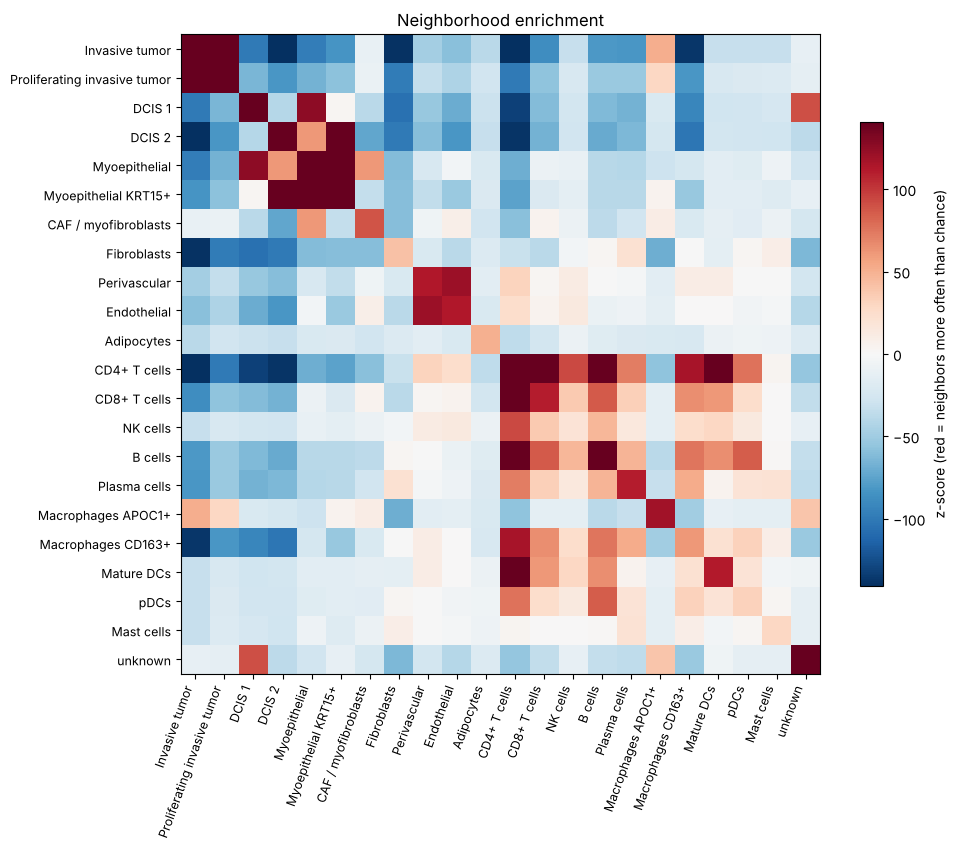

In [26]:
z = pd.DataFrame(adata.uns["cell_type_nhood_enrichment"]["zscore"], index=order, columns=order)
vmax = np.nanpercentile(np.abs(z.values), 95)            # robust color range

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(z.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(len(order)), order, rotation=70, ha="right", fontsize=9)
ax.set_yticks(range(len(order)), order, fontsize=9)
plt.colorbar(im, ax=ax, shrink=0.7, label="z-score (red = neighbors more often than chance)")
ax.set_title("Neighborhood enrichment")
plt.tight_layout(); plt.savefig(FIG_DIR / "xenium_nhood_enrichment.png", dpi=120); plt.show()

In [27]:
# for each type: its strongest neighbor partner (excluding itself)
zz = z.mask(np.eye(len(order), dtype=bool))      # hide the diagonal
partners = pd.DataFrame({"self z": np.diag(z.values).round(0),
                         "top partner": zz.idxmax(axis=1),
                         "partner z": zz.max(axis=1).round(0)}, index=order)
partners

,self z,top partner,partner z
Invasive tumor,364.0,Proliferating invasive tumor,295.0
Proliferating invasive tumor,211.0,Invasive tumor,295.0
DCIS 1,681.0,Myoepithelial,127.0
DCIS 2,745.0,Myoepithelial KRT15+,141.0
Myoepithelial,297.0,Myoepithelial KRT15+,145.0
Myoepithelial KRT15+,621.0,Myoepithelial,145.0
CAF / myofibroblasts,89.0,Myoepithelial,61.0
Fibroblasts,41.0,Plasma cells,22.0
Perivascular,113.0,Endothelial,121.0
Endothelial,113.0,Perivascular,121.0


**What the spatial check shows.** The labels came from expression alone, and the tissue pattern is consistent with them (one section, one patient; descriptive, not a significance test):

- **Tumor forms structures, not noise.** Every tumor type is strongly self-enriched (z of a few hundred). Invasive tumor and its proliferating part form one contiguous sheet (left). The two DCIS groups fill separate, round ducts (center and right).
- **DCIS keeps its myoepithelial ring; invasive tumor does not.** DCIS 1 and DCIS 2 have myoepithelial cells as their top partners (z ≈ 130–140). Invasive tumor is depleted of myoepithelial neighbors (negative z). Loss of the myoepithelial layer is what separates invasive from in-situ disease, and it was recovered here without using position to name the cells.
- **Vessels:** endothelial and perivascular cells are each other's top partner (z ≈ 120).
- **Lymphoid aggregates:** CD4+ T and B cells co-localize strongly (z ≈ 250), joined by mature DCs and pDCs. This is the pattern of tertiary-lymphoid-like structures.
- **Myeloid niches:** APOC1+ macrophages sit next to invasive tumor; CD163+ macrophages sit with T cells.
- **`unknown` is spatially compact** (high self z, mostly at the tissue edge). This supports reading it as an edge or low-quality artifact rather than a hidden cell type.

## Save

`results/xenium_annotated.h5ad` holds my labels (`obs["cell_type"]`), the clusters, the PCA and the coordinates. It is the input to notebooks 03 and 04.
`.X` holds log-normalized expression; raw counts are in `layers["counts"]`.

In [28]:
adata.X = adata.layers.pop("lognorm")
adata.write_h5ad(RESULTS_DIR / "xenium_annotated.h5ad", compression="gzip")
adata

AnnData object with n_obs × n_vars = 164000 × 313
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'n_counts', 'leiden_0.2', 'leiden_0.4', 'leiden_0.6', 'leiden_0.8', 'leiden_1.0', 'leiden_1.2', 'cluster', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mean', 'std'
    uns: 'log1p', 'pca', 'neighbors', 'umap', 'leiden_0.2', 'leiden_0.4', 'leiden_0.6', 'leiden_0.8', 'leiden_1.0', 'leiden_1.2', 'rank_genes_groups', 'cluster_colors', 'cell_type_colors', 'spatial_neighbors', 'cell_type_nhood_enrichment'
    obsm: 'spatial', 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities', 'spatial_connectivities', 'spatial_distances'
    layers: None (.X), 'counts'

## References

- Janesick A. et al. High resolution mapping of the tumor microenvironment using integrated single-cell, spatial and in situ analysis. *Nat Commun* 14, 8353 (2023).
- Salas S. M. et al. Optimizing Xenium In Situ data utility by quality assessment and best-practice analysis workflows. *Nat Methods* (2025).
- Atta L. et al. Gene count normalization in single-cell imaging-based spatially resolved transcriptomics. *Genome Biol* 25 (2024).
- Palla G. et al. Squidpy: a scalable framework for spatial omics analysis. *Nat Methods* 19, 171–178 (2022).
- Traag V. A. et al. From Louvain to Leiden: guaranteeing well-connected communities. *Sci Rep* 9, 5233 (2019).